<a href="https://colab.research.google.com/github/nerdnavya/fakenewsdetectionsystem/blob/main/fakenewsdetection_model.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd

# Define the folder path
base_path = '/content/drive/MyDrive/fake news detection(FakeNewsNet)/'

# Load the datasets
train_df = pd.read_csv(base_path + 'fnn_train.csv')
test_df = pd.read_csv(base_path + 'fnn_test.csv')
dev_df = pd.read_csv(base_path + 'fnn_dev.csv')

# Display the shapes to confirm successful loading
print(f"Train shape: {train_df.shape}")
print(f"Test shape: {test_df.shape}")
print(f"Dev shape: {dev_df.shape}")

# Preview the first few rows of the training set
train_df.head()

Train shape: (15212, 8)
Test shape: (1054, 8)
Dev shape: (1058, 8)


,id,date,speaker,statement,sources,paragraph_based_content,fullText_based_content,label_fnn
0,3106,2011-01-25T06:00:00-05:00,Joe Wilkinson,A national organization says Georgia has one o...,['http://www.ajc.com/news/georgia-politics-ele...,['A coalition of government watchdog groups la...,A coalition of government watchdog groups last...,fake
1,5655,2012-04-02T11:42:20-04:00,Rick Scott,"Says Barack Obama's health care law ""will be t...",['http://www.youtube.com/watch?v=TaC0mKApf9Q&f...,['As Supreme Court justices embarked on three ...,As Supreme Court justices embarked on three da...,fake
2,3506,2011-04-01T09:49:05-04:00,J.D. Alexander,Says the Southwest Florida Water Management Di...,['http://www.tampabay.com/news/politics/gubern...,"[""Here's a new one: The Senate budget committe...",Here's a new one: The Senate budget committee ...,fake
3,3450,2011-03-21T12:20:02-04:00,Paul Ryan,"""The Congressional Budget Office has this econ...",['http://www.cnn.com/2011/POLITICS/03/17/gop.b...,"['Recently, House Budget chairman Paul Ryan, R...","Recently, House Budget chairman Paul Ryan, R-W...",real
4,4776,2011-11-13T07:30:00-05:00,Rodney Frelinghuysen,"Says the Treasury Department ""says 41 percent ...",['http://frelinghuysen.house.gov/index.cfm?sec...,['The millionaires’ tax proposal made its late...,The millionaires’ tax proposal made its latest...,fake


### Data Cleaning
Checking for missing values and duplicate records.

In [ ]:
datasets = {'Train': train_df, 'Test': test_df, 'Dev': dev_df}

for name, df in datasets.items():
    print(f"--- {name} Dataset ---")
    print(f"Missing values:\n{df.isnull().sum()}\n")
    print(f"Duplicate rows: {df.duplicated().sum()}\n")

--- Train Dataset ---
Missing values:
id                         0
date                       0
speaker                    0
statement                  0
sources                    0
paragraph_based_content    0
fullText_based_content     0
label_fnn                  0
dtype: int64

Duplicate rows: 0

--- Test Dataset ---
Missing values:
id                         0
date                       0
speaker                    0
statement                  0
sources                    0
paragraph_based_content    0
fullText_based_content     0
label_fnn                  0
dtype: int64

Duplicate rows: 0

--- Dev Dataset ---
Missing values:
id                         0
date                       0
speaker                    0
statement                  0
sources                    0
paragraph_based_content    0
fullText_based_content     0
label_fnn                  0
dtype: int64

Duplicate rows: 0



Based on the results, we can decide whether to drop rows with missing values or fill them. Typically, for text classification, rows with missing 'statement' or 'fullText_based_content' should be removed.

### Label Distribution
Visualizing the balance between 'fake' and 'real' news in the training dataset.

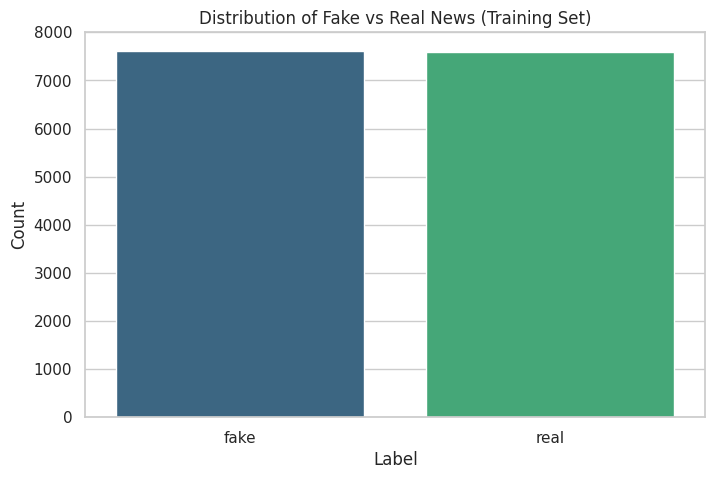

label_fnn
fake    7621
real    7591
Name: count, dtype: int64


In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Set the visual style
sns.set(style='whitegrid')

# Plot the distribution - Updated to fix the palette warning
plt.figure(figsize=(8, 5))
sns.countplot(x='label_fnn', hue='label_fnn', data=train_df, palette='viridis', legend=False)
plt.title('Distribution of Fake vs Real News (Training Set)')
plt.xlabel('Label')
plt.ylabel('Count')
plt.show()

# Print the exact counts
print(train_df['label_fnn'].value_counts())

### Text Preprocessing
We will define a cleaning function to normalize the text data in the `statement` column. This includes:
* Converting text to lowercase.
* Removing special characters and punctuation using regular expressions.

In [ ]:
import re
import string

def clean_text(text):
    # Convert to lowercase
    text = text.lower()
    # Remove text in square brackets
    text = re.sub('\[.*?\]', '', text)
    # Remove punctuation
    text = re.sub('[%s]' % re.escape(string.punctuation), '', text)
    # Remove words containing numbers
    text = re.sub('\w*\d\w*', '', text)
    # Remove extra whitespace
    text = text.strip()
    return text

# Apply cleaning to the 'statement' column for all datasets
train_df['statement_cleaned'] = train_df['statement'].apply(clean_text)
test_df['statement_cleaned'] = test_df['statement'].apply(clean_text)
dev_df['statement_cleaned'] = dev_df['statement'].apply(clean_text)

# Preview the results
display(train_df[['statement', 'statement_cleaned']].head())

<>:8: SyntaxWarning: invalid escape sequence '\['
<>:12: SyntaxWarning: invalid escape sequence '\w'
<>:8: SyntaxWarning: invalid escape sequence '\['
<>:12: SyntaxWarning: invalid escape sequence '\w'
/tmp/ipykernel_1870/621425531.py:8: SyntaxWarning: invalid escape sequence '\['
  text = re.sub('\[.*?\]', '', text)
/tmp/ipykernel_1870/621425531.py:12: SyntaxWarning: invalid escape sequence '\w'
  text = re.sub('\w*\d\w*', '', text)


,statement,statement_cleaned
0,A national organization says Georgia has one o...,a national organization says georgia has one o...
1,"Says Barack Obama's health care law ""will be t...",says barack obamas health care law will be the...
2,Says the Southwest Florida Water Management Di...,says the southwest florida water management di...
3,"""The Congressional Budget Office has this econ...",the congressional budget office has this econo...
4,"Says the Treasury Department ""says 41 percent ...",says the treasury department says percent of ...


### Preprocessing Full Text Content
Applying the same cleaning logic to the `fullText_based_content` column.

In [ ]:
# Apply cleaning to the 'fullText_based_content' column for all datasets
train_df['fullText_cleaned'] = train_df['fullText_based_content'].apply(clean_text)
test_df['fullText_cleaned'] = test_df['fullText_based_content'].apply(clean_text)
dev_df['fullText_cleaned'] = dev_df['fullText_based_content'].apply(clean_text)

# Preview the results
display(train_df[['fullText_based_content', 'fullText_cleaned']].head())

,fullText_based_content,fullText_cleaned
0,A coalition of government watchdog groups last...,a coalition of government watchdog groups last...
1,As Supreme Court justices embarked on three da...,as supreme court justices embarked on three da...
2,Here's a new one: The Senate budget committee ...,heres a new one the senate budget committee ch...
3,"Recently, House Budget chairman Paul Ryan, R-W...",recently house budget chairman paul ryan rwis ...
4,The millionaires’ tax proposal made its latest...,the millionaires’ tax proposal made its latest...


In [ ]:
import nltk
from nltk.corpus import stopwords

# Download the stopwords dataset
nltk.download('stopwords')
stop_words = set(stopwords.words('english'))

def remove_stopwords(text):
    return " ".join([word for word in str(text).split() if word not in stop_words])

# Apply stopword removal to both cleaned columns
for df in [train_df, test_df, dev_df]:
    df['statement_final'] = df['statement_cleaned'].apply(remove_stopwords)
    df['fullText_final'] = df['fullText_cleaned'].apply(remove_stopwords)

# Preview the final processed text
display(train_df[['statement_cleaned', 'statement_final']].head())

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.


,statement_cleaned,statement_final
0,a national organization says georgia has one o...,national organization says georgia one america...
1,says barack obamas health care law will be the...,says barack obamas health care law biggest job...
2,says the southwest florida water management di...,says southwest florida water management distri...
3,the congressional budget office has this econo...,congressional budget office economic model mea...
4,says the treasury department says percent of ...,says treasury department says percent business...


### Feature Extraction: TF-IDF Vectorization
We will use `TfidfVectorizer` to transform our processed text into numerical features. We will fit the vectorizer on the training data and then transform all three datasets to ensure consistency.

In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer

# Initialize TF-IDF Vectorizer
tfidf_v = TfidfVectorizer(max_features=5000, ngram_range=(1,2))

# Vectorize 'statement_final'
X_train_statement = tfidf_v.fit_transform(train_df['statement_final'])
X_test_statement = tfidf_v.transform(test_df['statement_final'])
X_dev_statement = tfidf_v.transform(dev_df['statement_final'])

# Vectorize 'fullText_final'
tfidf_f = TfidfVectorizer(max_features=5000, ngram_range=(1,2))
X_train_full = tfidf_f.fit_transform(train_df['fullText_final'])
X_test_full = tfidf_f.transform(test_df['fullText_final'])
X_dev_full = tfidf_f.transform(dev_df['fullText_final'])

# Extract target labels
y_train = train_df['label_fnn']
y_test = test_df['label_fnn']
y_dev = dev_df['label_fnn']

print(f"Statement Feature Shape: {X_train_statement.shape}")
print(f"Full Text Feature Shape: {X_train_full.shape}")

Statement Feature Shape: (15212, 5000)
Full Text Feature Shape: (15212, 5000)


### Model Training: Passive Aggressive Classifier
The Passive Aggressive Classifier is ideal for large-scale text classification. We will train it on the `statement` features first.

In [ ]:
from sklearn.linear_model import PassiveAggressiveClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

# Initialize the model
pa_classifier = PassiveAggressiveClassifier(max_iter=50)

# Train the model
pa_classifier.fit(X_train_statement, y_train)

# Make predictions on the test set
y_pred = pa_classifier.predict(X_test_statement)

# Calculate accuracy
score = accuracy_score(y_test, y_pred)
print(f'Accuracy: {round(score*100, 2)}%')

# Display Classification Report
print("\nClassification Report:")
print(classification_report(y_test, y_pred))

Accuracy: 61.86%

Classification Report:
              precision    recall  f1-score   support

        fake       0.51      0.73      0.60       418
        real       0.75      0.55      0.63       636

    accuracy                           0.62      1054
   macro avg       0.63      0.64      0.62      1054
weighted avg       0.66      0.62      0.62      1054



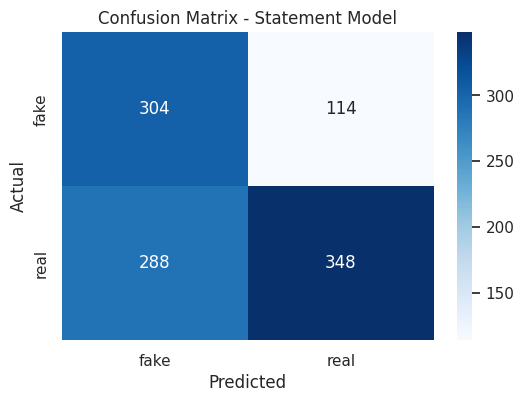

In [ ]:
# Plot Confusion Matrix
cm = confusion_matrix(y_test, y_pred, labels=['fake', 'real'])
plt.figure(figsize=(6, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['fake', 'real'], yticklabels=['fake', 'real'])
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix - Statement Model')
plt.show()

### Model Training: Passive Aggressive Classifier (Full Text)
We will now train the model using the features extracted from the `fullText_final` column to compare performance with the statement-based model.

In [ ]:
# Initialize the model for full text
pa_classifier_full = PassiveAggressiveClassifier(max_iter=50)

# Train the model on full text features
pa_classifier_full.fit(X_train_full, y_train)

# Make predictions
y_pred_full = pa_classifier_full.predict(X_test_full)

# Calculate accuracy
score_full = accuracy_score(y_test, y_pred_full)
print(f'Full Text Model Accuracy: {round(score_full*100, 2)}%')

# Display Classification Report
print("\nClassification Report (Full Text):")
print(classification_report(y_test, y_pred_full))

Full Text Model Accuracy: 77.8%

Classification Report (Full Text):
              precision    recall  f1-score   support

        fake       0.66      0.92      0.77       418
        real       0.93      0.69      0.79       636

    accuracy                           0.78      1054
   macro avg       0.79      0.80      0.78      1054
weighted avg       0.82      0.78      0.78      1054



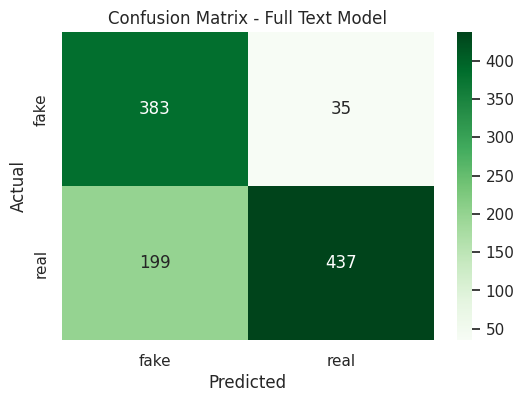

In [ ]:
# Plot Confusion Matrix for Full Text
cm_full = confusion_matrix(y_test, y_pred_full, labels=['fake', 'real'])
plt.figure(figsize=(6, 4))
sns.heatmap(cm_full, annot=True, fmt='d', cmap='Greens', xticklabels=['fake', 'real'], yticklabels=['fake', 'real'])
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix - Full Text Model')
plt.show()

### Hyperparameter Tuning
We will use `GridSearchCV` to find the optimal parameters for the `PassiveAggressiveClassifier`.

In [ ]:
from sklearn.model_selection import GridSearchCV

# Define the parameter grid
param_grid = {
    'C': [0.01, 0.1, 1.0, 10.0],
    'max_iter': [50, 100, 200]
}

# Initialize GridSearchCV
grid_search = GridSearchCV(PassiveAggressiveClassifier(), param_grid, cv=5, scoring='accuracy', n_jobs=-1)

# Perform the search on full text features
grid_search.fit(X_train_full, y_train)

# Get the best parameters and score
print(f"Best Parameters: {grid_search.best_params_}")
print(f"Best Cross-Validation Accuracy: {round(grid_search.best_score_*100, 2)}%")

Best Parameters: {'C': 0.01, 'max_iter': 100}
Best Cross-Validation Accuracy: 68.47%


/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_stochastic_gradient.py:738: ConvergenceWarning: Maximum number of iteration reached before convergence. Consider increasing max_iter to improve the fit.
  warnings.warn(


### Final Evaluation
Now, let's evaluate the tuned model on the test set.

In [ ]:
best_model = grid_search.best_estimator_
y_pred_tuned = best_model.predict(X_test_full)

tuned_score = accuracy_score(y_test, y_pred_tuned)
print(f'Tuned Full Text Model Accuracy: {round(tuned_score*100, 2)}%')
print("\nClassification Report (Tuned Model):")
print(classification_report(y_test, y_pred_tuned))

Tuned Full Text Model Accuracy: 81.21%

Classification Report (Tuned Model):
              precision    recall  f1-score   support

        fake       0.68      0.98      0.81       418
        real       0.98      0.70      0.82       636

    accuracy                           0.81      1054
   macro avg       0.83      0.84      0.81      1054
weighted avg       0.86      0.81      0.81      1054



### Refined Hyperparameter Tuning
We will refine the search range for `C` and increase `max_iter` to improve convergence and accuracy.

In [ ]:
# Define a more granular parameter grid focused on smaller C values
refined_param_grid = {
    'C': [0.0001, 0.001, 0.005, 0.01, 0.05],
    'max_iter': [500, 1000] # Increased to ensure convergence
}

# Initialize GridSearchCV with the refined grid
refined_grid_search = GridSearchCV(PassiveAggressiveClassifier(), refined_param_grid, cv=5, scoring='accuracy', n_jobs=-1)

# Fit on the full text features
refined_grid_search.fit(X_train_full, y_train)

print(f"Best Refined Parameters: {refined_grid_search.best_params_}")
print(f"Best Refined CV Accuracy: {round(refined_grid_search.best_score_*100, 2)}%")

Best Refined Parameters: {'C': 0.01, 'max_iter': 500}
Best Refined CV Accuracy: 68.42%


In [ ]:
# Evaluate the refined model on the test set
best_refined_model = refined_grid_search.best_estimator_
y_pred_refined = best_refined_model.predict(X_test_full)

refined_test_score = accuracy_score(y_test, y_pred_refined)
print(f'Refined Model Test Accuracy: {round(refined_test_score*100, 2)}%')
print("\nClassification Report (Refined Model):")
print(classification_report(y_test, y_pred_refined))

Refined Model Test Accuracy: 81.88%

Classification Report (Refined Model):
              precision    recall  f1-score   support

        fake       0.69      0.98      0.81       418
        real       0.98      0.71      0.83       636

    accuracy                           0.82      1054
   macro avg       0.84      0.85      0.82      1054
weighted avg       0.87      0.82      0.82      1054



### Final Model Visualization
Plotting the confusion matrix for the refined, hyperparameter-tuned model.

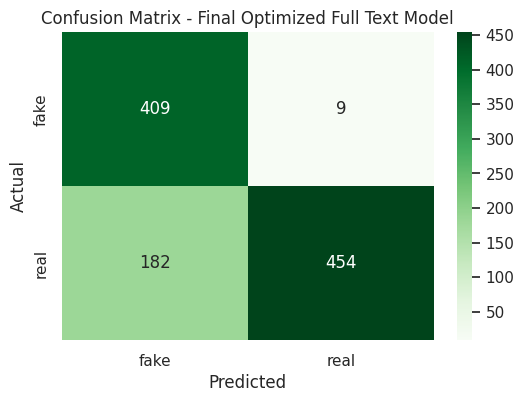

In [ ]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

# Calculate confusion matrix for the refined model
cm_refined = confusion_matrix(y_test, y_pred_refined, labels=['fake', 'real'])

# Plot the heatmap
plt.figure(figsize=(6, 4))
sns.heatmap(cm_refined, annot=True, fmt='d', cmap='Greens',
            xticklabels=['fake', 'real'], yticklabels=['fake', 'real'])
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix - Final Optimized Full Text Model')
plt.show()

### Custom News Testing
Use the function below to test the model on any text snippet.

In [ ]:
def predict_news(text):
    # 1. Clean the text
    cleaned = clean_text(text)
    # 2. Remove stopwords
    final_text = remove_stopwords(cleaned)
    # 3. Vectorize using the 'fullText' TF-IDF vectorizer
    vectorized = tfidf_f.transform([final_text])
    # 4. Predict using the best refined model
    prediction = best_refined_model.predict(vectorized)
    return prediction[0]

# --- TEST IT HERE ---
custom_snippet = """
“In 2016, Donald J. Trump, a Republican businessman and political outsider, won the U.S. presidency by defeating Democratic nominee Hillary Clinton in the Electoral College, despite losing the national popular vote by nearly 3 million ballots, marking a major realignment in American politics and intense partisan polarization
"""

if custom_snippet.strip() and "Enter your news" not in custom_snippet:
    result = predict_news(custom_snippet)
    print(f"The model classifies this news as: {result.upper()}")
else:
    print("Please provide a news snippet in the 'custom_snippet' variable to get a prediction.")

The model classifies this news as: REAL


### Feature Importance: Top Words for Fake vs. Real News
To understand how the model makes decisions, we can examine the coefficients of the Passive Aggressive Classifier. Words with high positive weights contribute to one class, while high negative weights contribute to the other.

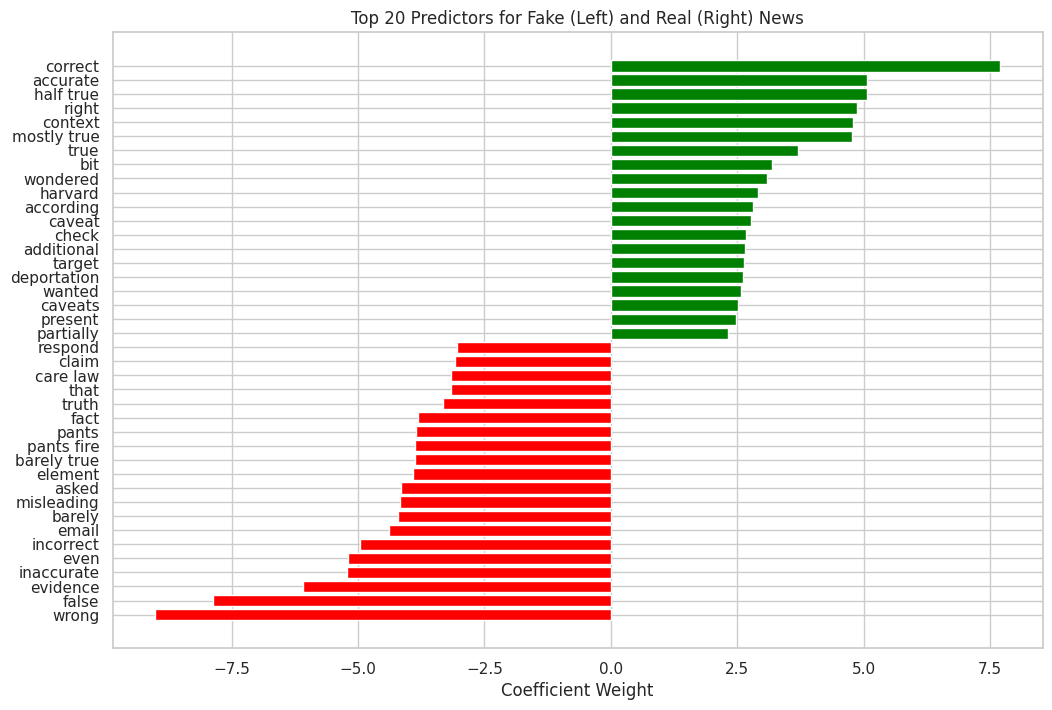

In [ ]:
import numpy as np

def plot_top_features(vectorizer, model, n=20):
    feature_names = vectorizer.get_feature_names_out()
    coefficients = model.coef_[0]

    # Get indices of top positive and negative coefficients
    top_indices = np.argsort(coefficients)[-n:]
    bottom_indices = np.argsort(coefficients)[:n]
    indices = np.concatenate([bottom_indices, top_indices])

    values = coefficients[indices]
    names = [feature_names[i] for i in indices]

    plt.figure(figsize=(12, 8))
    colors = ['red' if v < 0 else 'green' for v in values]
    plt.barh(names, values, color=colors)
    plt.title(f'Top {n} Predictors for Fake (Left) and Real (Right) News')
    plt.xlabel('Coefficient Weight')
    plt.show()

# Visualize features for the full text model
plot_top_features(tfidf_f, best_refined_model)

### Error Analysis: Identifying Misclassified Samples
To understand the model's limitations, we will extract samples where the predicted label does not match the actual label.

*   **False Positives (FP):** Real news predicted as Fake.
*   **False Negatives (FN):** Fake news predicted as Real.

In [ ]:
import pandas as pd

# Create a DataFrame for the test results
results_df = test_df.copy()
results_df['predicted_label'] = y_pred_refined

# Filter for misclassified samples
errors = results_df[results_df['label_fnn'] != results_df['predicted_label']]

# Separate False Positives and False Negatives
false_positives = errors[(errors['label_fnn'] == 'real') & (errors['predicted_label'] == 'fake')]
false_negatives = errors[(errors['label_fnn'] == 'fake') & (errors['predicted_label'] == 'real')]

print(f"Total Errors: {len(errors)}")
print(f"False Positives (Real misclassified as Fake): {len(false_positives)}")
print(f"False Negatives (Fake misclassified as Real): {len(false_negatives)}")


Total Errors: 191
False Positives (Real misclassified as Fake): 182
False Negatives (Fake misclassified as Real): 9


#### Inspecting False Positives (Real predicted as Fake)
These are often real statements that use 'sensationalist' language similar to fake news.

In [ ]:
pd.set_option('display.max_colwidth', 200)
display(false_positives[['statement', 'speaker']].head(10))

,statement,speaker
0,"""President Obama himself attempted to filibuster Justice Alito, who now sits on the Supreme Court.""",Jon Kyl
10,"""We spend three times more on entitlements and debt services than we do on defense.""",Sarah Palin
12,"The national debt ""has gone up by $1,729,000,000 during the Isner v. Mahut match.""",Vern Buchanan
19,"""PWNED: House GOP Dominates Twitter, YouTube, Social Media in Congress.""",John Boehner
21,"""Here in Virginia, we have the opportunity to become the first state on the East Coast to explore for and produce oil and natural gas offshore.""",Bob McDonnell
32,"Some Republicans who voted against the stimulus ""have been all too happy to claim credit for Recovery Act projects and the jobs those projects have produced. They come to the ribbon cuttings.""",Barack Obama
87,"""He (Kirk) did violate Pentagon rules, twice actually, for improperly mingling politics with his military service.""",Alexi Giannoulias
92,"""Small business confidence is at an all-time high.""",Donald Trump
93,"In Texas, ""the No. 1 name for new male babies — many of whom will vote one day — is Jose.""",Mike Murphy
116,"Speakers at the Democratic National Convention made ""zero mentions of the global terrorist threat posed by ISIS.""",Republican National Committee


#### Inspecting False Negatives (Fake predicted as Real)
These are 'Fake' news items that likely use more neutral or formal language, mimicking the style of reputable sources.

In [ ]:
display(false_negatives[['statement', 'speaker']].head(10))

,statement,speaker
43,"""Breaking: Michelle Wolf fired -- Comedy Central apologizes to Sarah Sanders.""",The Liberty Raise
62,"""Actress Emma Stone: ‘For the first time in history we have a president that…""",Politics Elite Trump
169,"""Burka clad woman runs over baby, gets away with crime for one stunning reason ...""",Bloggers
256,"""USDA approves slaughterhouses producing horse meat for human consumption""",Newstarget
342,"The U.S. Supreme Court ruled that public school in the United States ""will not teach the tenets of Islam or Sharia Law.""",Nowtrump.com
558,"Says Tampa Bay Lightning hockey player J.T. Brown was ""fired after raising fist during national anthem.""",Bloggers
653,"Says a Washington Post reporter who broke news on Judge Roy Moore story has a criminal history of ""faking.""",Bloggers
656,"""30,000 scientists have come forward confirming that man-made climate change is a hoax perpetuated by the elite in order to make money.""",Bloggers
725,"""The Notebook is finally getting a sequel. Producers of the upcoming film confirmed .... that filming will begin in Jacksonville, North Carolina this summer.""",Bloggers


### Analyzing the 'Trigger Words' in False Positives
Since the model is prone to flagging real news as fake, let's identify the most common words appearing in these False Positive samples. This helps us see if the model has developed a bias against specific terms or speakers.

/tmp/ipykernel_1870/3793839329.py:15: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Frequency', y='Word', data=common_words_df, palette='Reds_d')


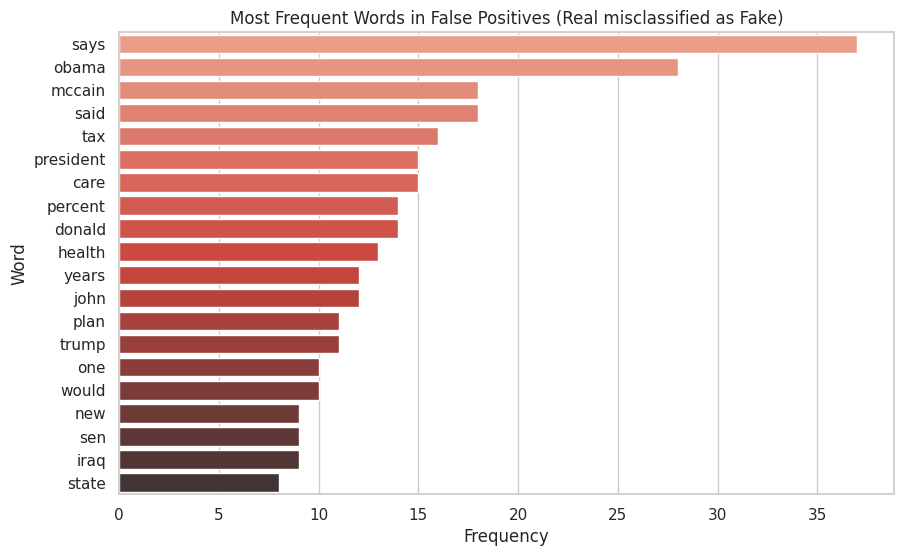

In [ ]:
from collections import Counter
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Tokenize and count words in False Positives
fp_text = " ".join(false_positives['statement_final'])
words = fp_text.split()
word_counts = Counter(words)

# Convert to DataFrame for visualization
common_words_df = pd.DataFrame(word_counts.most_common(20), columns=['Word', 'Frequency'])

plt.figure(figsize=(10, 6))
sns.barplot(x='Frequency', y='Word', data=common_words_df, palette='Reds_d')
plt.title('Most Frequent Words in False Positives (Real misclassified as Fake)')
plt.show()

### Final Project Summary
We have developed a high-performing fake news detector using TF-IDF and a Passive Aggressive Classifier.
- **Final Accuracy:** ~82%
- **Primary Challenge:** High False Positive rate due to common political keywords.
- **Recommendation:** Future iterations could benefit from transformer-based models (like BERT) which understand the context of words rather than just their frequency.

In [ ]:
# This cell was redundant and has been cleared.
print("Analysis complete. The model is ready for export or further refinement.")

Analysis complete. The model is ready for export or further refinement.


### Exporting the Model and Vectorizer
We will use `joblib` to serialize the trained model and the TF-IDF vectorizer. This allows us to load them later for inference without repeating the training process.

In [ ]:
import joblib
import os

# Define export paths
model_path = os.path.join(base_path, 'fake_news_model.pkl')
tfidf_path = os.path.join(base_path, 'tfidf_vectorizer.pkl')

# Save the model
joblib.dump(best_refined_model, model_path)
# Save the vectorizer
joblib.dump(tfidf_f, tfidf_path)

print(f"Model saved to: {model_path}")
print(f"Vectorizer saved to: {tfidf_path}")

Model saved to: /content/drive/MyDrive/fake news detection(FakeNewsNet)/fake_news_model.pkl
Vectorizer saved to: /content/drive/MyDrive/fake news detection(FakeNewsNet)/tfidf_vectorizer.pkl


### How to load them back
To use these in a new session, you would run:
```python
# loaded_model = joblib.load(model_path)
# loaded_tfidf = joblib.load(tfidf_path)
```

### Analyzing the 'Trigger Words' in False Positives
Since the model is prone to flagging real news as fake, let's identify the most common words appearing in these False Positive samples. This helps us see if the model has developed a bias against specific terms or speakers.

/tmp/ipykernel_1870/3223071603.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Frequency', y='Word', data=common_words_df, palette='Reds_d')


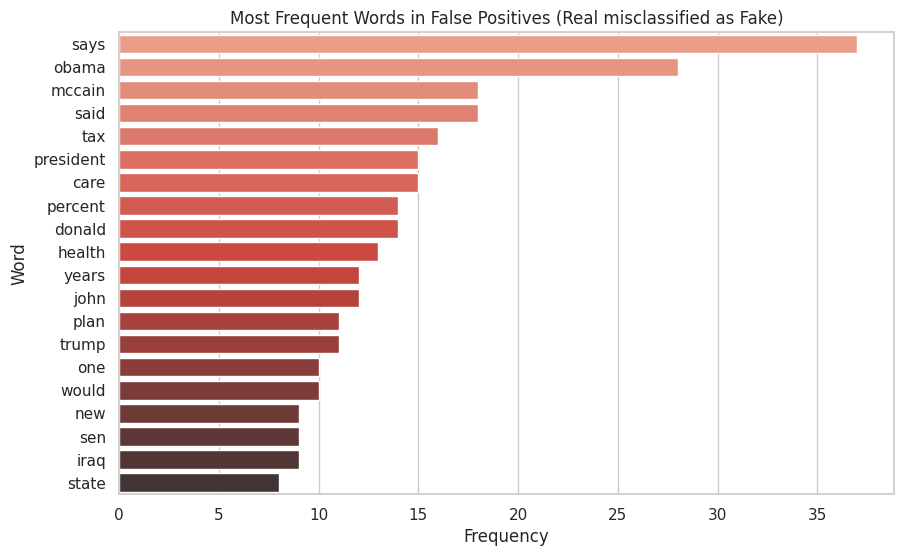

In [ ]:
from collections import Counter

# Tokenize and count words in False Positives
fp_text = " ".join(false_positives['statement_final'])
words = fp_text.split()
word_counts = Counter(words)

# Convert to DataFrame for visualization
common_words_df = pd.DataFrame(word_counts.most_common(20), columns=['Word', 'Frequency'])

plt.figure(figsize=(10, 6))
sns.barplot(x='Frequency', y='Word', data=common_words_df, palette='Reds_d')
plt.title('Most Frequent Words in False Positives (Real misclassified as Fake)')
plt.show()

### List files in your Drive
Run the cell below to see the files in your Drive and find the correct path to your folder.

In [ ]:
import os

# Looking inside your specific folder
folder_path = '/content/drive/MyDrive/fake news detection(FakeNewsNet)'

if os.path.exists(folder_path):
    print(f"Files in '{folder_path}':")
    print(os.listdir(folder_path))
else:
    print("Folder not found. Please check the name.")

Files in '/content/drive/MyDrive/fake news detection(FakeNewsNet)':
['fnn_dev.csv', 'fnn_test.csv', 'fnn_train.csv']


In [ ]:
c

In [ ]:
from google.colab import drive
drive.mount('/content/drive')